# 02 · CUPED variance reduction · MMM · Power / MDE

Three experimentation-craft techniques on the same synthetic geo panel.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
os.chdir(os.path.abspath(".."))  # run from repo root so data/ paths resolve
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import generate_data
if not os.path.exists("data/geo_panel.csv"):
    generate_data.main()
df = pd.read_csv("data/geo_panel.csv")
import json
gt = json.load(open("data/ground_truth.json"))
print("Ground-truth injected lift:", f"{gt['true_lift']:+.0%}")
df.head()

Ground-truth injected lift: +12%


,geo,date,day,treated,post,spend,conversions,conversions_counterfactual
0,DMA_00,2025-01-01,0,0,0,0.0,3102.913,3102.913
1,DMA_00,2025-01-02,1,0,0,0.0,3479.592,3479.592
2,DMA_00,2025-01-03,2,0,0,0.0,3530.085,3530.085
3,DMA_00,2025-01-04,3,0,0,0.0,3476.069,3476.069
4,DMA_00,2025-01-05,4,0,0,0.0,3131.462,3131.462


## CUPED (Controlled experiment Using Pre-Existing Data)
Regress out a pre-period covariate correlated with the outcome to shrink variance — a smaller SE means a smaller detectable effect for the same sample.

In [2]:
from src import cuped
frame = cuped.geo_level_frame(df)
rc = cuped.cuped_adjust(frame)
print(f"corr(pre, post) = {rc['corr_xy']:.3f}")
print(f"Naive  lift={rc['naive']['lift']:+.2%}  SE={rc['naive']['se']:.4f}")
print(f"CUPED  lift={rc['cuped']['lift']:+.2%}  SE={rc['cuped']['se']:.4f}")
print(f"Variance reduction={rc['var_reduction']:.1%}  SE reduction={rc['se_reduction']:.1%}")

corr(pre, post) = 0.983
Naive  lift=+9.35%  SE=0.1032
CUPED  lift=+11.99%  SE=0.0031
Variance reduction=99.9%  SE reduction=97.0%


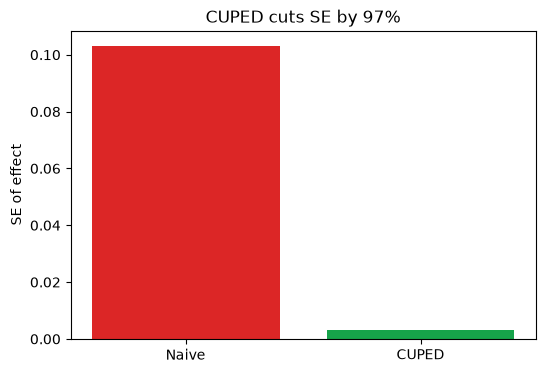

In [3]:
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(['Naive','CUPED'], [rc['naive']['se'], rc['cuped']['se']], color=['#dc2626','#16a34a'])
ax.set_ylabel('SE of effect'); ax.set_title(f"CUPED cuts SE by {rc['se_reduction']:.0%}"); plt.show()

## Marketing Mix Model (adstock + Hill saturation)
Transform spend with geometric adstock (carryover) and a Hill saturation curve (diminishing returns), then regress conversions on the transformed media with geo & weekday controls.

In [4]:
from src import mmm
rm = mmm.fit_mmm(df, decay=0.5, shape=1.5)
print(f"decay={rm['decay']} shape={rm['shape']} half_sat={rm['half_sat']:.1f}")
print(f"beta(media)={rm['beta_media']:.1f}  R^2={rm['r2']:.3f}")

decay=0.5 shape=1.5 half_sat=196.2
beta(media)=1039.8  R^2=0.965


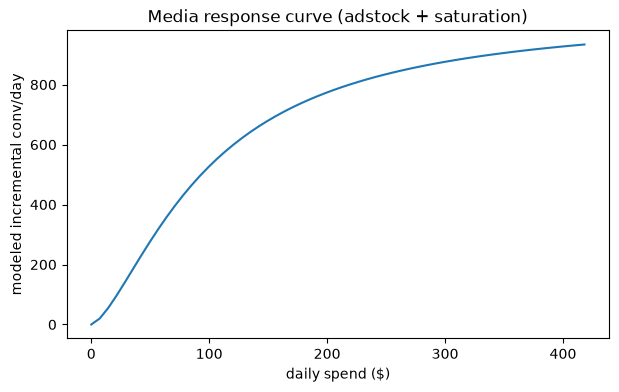

In [5]:
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(rm['spend_grid'], rm['response'])
ax.set_xlabel('daily spend ($)'); ax.set_ylabel('modeled incremental conv/day')
ax.set_title('Media response curve (adstock + saturation)'); plt.show()

## Power analysis / MDE
Given between-geo variance and design size, what lift can we reliably detect?

In [6]:
from src import power
var = power.variance_from_data(df)
n_t = int(df.groupby('geo')['treated'].first().sum())
n_c = int((df.groupby('geo')['treated'].first()==0).sum())
print(f"log-variance={var:.3f}  ({n_t} treated / {n_c} control)")
print(f"MDE @80% power = {power.mde(var,n_t,n_c):+.1%}")
print(f"Power to detect +12% = {power.power_for_lift(0.12,var,n_t,n_c):.0%}")

log-variance=0.100  (18 treated / 22 control)
MDE @80% power = +32.5%
Power to detect +12% = 20%


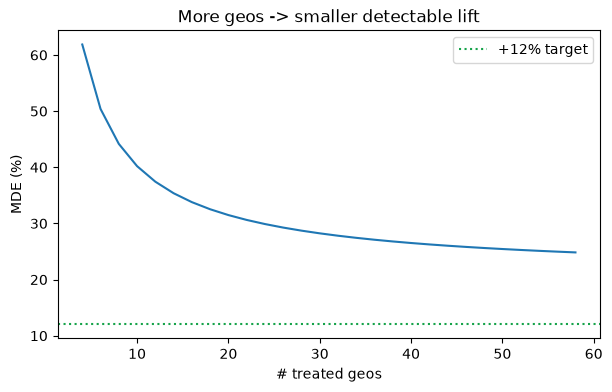

In [7]:
import numpy as np
n_grid = np.arange(4,60,2)
mdes = power.mde_curve(var, n_c, n_grid)
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(n_grid, [m*100 for m in mdes]); ax.axhline(12, ls=':', color='#16a34a', label='+12% target')
ax.set_xlabel('# treated geos'); ax.set_ylabel('MDE (%)'); ax.legend()
ax.set_title('More geos -> smaller detectable lift'); plt.show()

### Takeaway
CUPED is the cheapest way to buy power; MMM adds budget-allocation insight (saturation → diminishing returns); power/MDE sizing prevents underpowered geo tests. Together they cover the full experimentation lifecycle.